In [25]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F
from IPython.display import clear_output
warnings.filterwarnings("ignore")
clear_output()

In [26]:
def test(net):
    verbose = False
    # Evaluate performance of the trained model
    net.eval()
    # Initialize storage for each environment
    sl_mean_performance = {}
    for e_i in env.envs:
        sl_mean_performance[e_i.spec.id] = []

    # Evaluate for specified number of trials
    print(f"Evaluating model performance across {EVAL_TRIALS} trials...\n")

    for env_idx, e_i in enumerate(env.envs):
        data = {"action": [], "gt": [], "trial": []}
        total_correct = 0
        for trial_idx in range(EVAL_TRIALS):
            trial = e_i.new_trial()
            data["trial"].append(trial)
            ob, gt = e_i.ob, e_i.gt
            data["gt"].append(gt[-1])
            trial_length = ob.shape[0]

            # Add one-hot encoding for the environment
            env_one_hot = np.zeros((trial_length, len(env.envs)))
            env_one_hot[:, env_idx] = 1.0  # Set the current environment index to 1

            # Concatenate original observation with one-hot encoding
            ob_with_env = np.concatenate([ob, env_one_hot], axis=1)

            ob_with_env = ob_with_env[:, np.newaxis, :]  # Add batch dimension

            inputs = torch.from_numpy(ob_with_env).float().to(device)
            # hidden = sl_model.init_hidden(1, device)

            with torch.no_grad():
                outputs, _, hidden = net(inputs)
                pred_actions = torch.argmax(outputs, dim=2)
                data["action"].append(pred_actions[-1, 0].cpu().numpy())

            decision_idx = trial_length - 1
            is_correct = (gt[decision_idx] == pred_actions[decision_idx, 0].cpu().numpy())
            total_correct += is_correct

        accuracy = total_correct / EVAL_TRIALS
        sl_mean_performance[e_i.spec.id].append(accuracy)
        for key in data:
            if key != "trial":
                data[key] = np.array(data[key])


    # Print average performance
    print("Average performance across all environments:")
    mean_acc_all = np.array([np.mean(sl_mean_performance[e_i.spec.id]) for e_i in env.envs])
    for e_i in env.envs:
        mean_acc = np.mean(sl_mean_performance[e_i.spec.id])
        print(f"{e_i.spec.id}: {mean_acc:.4f}")
    return mean_acc_all

def plot_test_performance(test_EI_acc, test_simple_acc, env_names, show_values=True):
    mean_ei = np.mean(test_EI_acc, axis=0)
    std_ei = np.std(test_EI_acc, axis=0)/np.sqrt(test_EI_acc.shape[0])
    mean_simple = np.mean(test_simple_acc, axis=0)
    std_simple = np.std(test_simple_acc, axis=0)/np.sqrt(test_simple_acc.shape[0])

    n_env = mean_ei.shape[0]
    x = np.arange(n_env)
    width = 0.35  # bar width

    fig, ax = plt.subplots(figsize=(12,4))

    bars_ei = ax.bar(x - width/2, mean_ei, width,
                     yerr=std_ei, capsize=4,
                     label='EI')
    bars_simple = ax.bar(x + width/2, mean_simple, width,
                         yerr=std_simple, capsize=4,
                         label='simple')

    relative_advantage = ((mean_ei - mean_simple) / (mean_ei + mean_simple) * 2).mean()
    ax.set_xticks(x)
    ax.set_xticklabels(env_names, rotation=30, ha='right')
    ax.set_ylabel('Test accuracy')
    ax.set_title(f'Model comparison across environments. EI Advantage: {relative_advantage:.2f}')
    ax.legend()

    if show_values:
        ax.bar_label(bars_ei, fmt='%.2f', padding=2)
        ax.bar_label(bars_simple, fmt='%.2f', padding=2)

    plt.tight_layout()

    plt.savefig('./output/multitask/yang19_test_performance.png')
    plt.show()

def plot_loss_curve(loss_log_ei, gradient_log_ei, loss_log_simple, gradient_log_simple,
                    spectral_radius_log_ei=None, spectral_radius_log_simple=None,
                    rec_balance_log_ei=None, rec_balance_log_simple=None):
    fig, ax = plt.subplots(1,4, figsize=(20, 5))
    fontsize = 15
    ax = ax.flatten()
    mean_ei = np.mean(loss_log_ei, axis=0)
    std_ei = np.std(loss_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(loss_log_simple, axis=0)
    std_simple = np.std(loss_log_simple, axis=0)
    loss_idx = 1
    ax[0].plot(mean_ei[:, loss_idx], label='EI', color='C0')
    ax[0].fill_between(np.arange(len(mean_ei)), mean_ei[:, loss_idx] - std_ei[:, loss_idx], mean_ei[:, loss_idx] + std_ei[:, loss_idx], alpha=0.2, color='C0')
    ax[0].plot(mean_simple[:, loss_idx], label='simple', color='C1')
    ax[0].fill_between(np.arange(len(mean_simple)), mean_simple[:, loss_idx] - std_simple[:, loss_idx], mean_simple[:, loss_idx] + std_simple[:, loss_idx], alpha=0.2, color='C1')
    ax[0].set_title('Loss', fontsize=fontsize)
    ax[0].set_xlabel('Epoch', fontsize=fontsize)
    ax[0].legend(fontsize=fontsize)

    mean_ei = np.mean(gradient_log_ei, axis=0)
    std_ei = np.std(gradient_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(gradient_log_simple, axis=0)
    std_simple = np.std(gradient_log_simple, axis=0)
    log_mean_ei = np.log(mean_ei[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    log_mean_simple = np.log(mean_simple[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    log_std_ei = np.log(std_ei[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    log_std_simple = np.log(std_simple[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    ax[1].plot(log_mean_ei, label='EI', color='C0')
    ax[1].fill_between(np.arange(len(mean_ei)), log_mean_ei - log_std_ei, log_mean_ei + log_std_ei, alpha=0.2, color='C0')
    ax[1].plot(log_mean_simple, label='simple', color='C1')
    ax[1].fill_between(np.arange(len(mean_simple)), log_mean_simple - log_std_simple, log_mean_simple + log_std_simple, alpha=0.2, color='C1')
    ax[1].set_title('Log Gradient norm', fontsize=fontsize)
    ax[1].set_xlabel('Epoch', fontsize=fontsize)
    ax[1].legend(fontsize=fontsize)

    if spectral_radius_log_ei is not None and spectral_radius_log_simple is not None:
        mean_ei = np.mean(spectral_radius_log_ei, axis=0)
        std_ei = np.std(spectral_radius_log_ei, axis=0)
        mean_simple = np.mean(spectral_radius_log_simple, axis=0)
        std_simple = np.std(spectral_radius_log_simple, axis=0)
        ax[2].plot(mean_ei[:, 0], label='EI', color='C0')
        ax[2].fill_between(np.arange(len(mean_ei)), mean_ei[:, 0] - std_ei[:, 0], mean_ei[:, 0] + std_ei[:, 0], alpha=0.2, color='C0')
        ax[2].plot(mean_simple[:, 0], label='simple', color='C1')
        ax[2].fill_between(np.arange(len(mean_simple)), mean_simple[:, 0] - std_simple[:, 0], mean_simple[:, 0] + std_simple[:, 0], alpha=0.2, color='C1')
        ax[2].set_title('Spectral radius', fontsize=fontsize)
        ax[2].set_xlabel('Epoch', fontsize=fontsize)
        ax[2].legend(fontsize=fontsize)

    if rec_balance_log_ei is not None and rec_balance_log_simple is not None:
        mean_ei = np.mean(rec_balance_log_ei, axis=(0,-1))
        std_ei = np.std(rec_balance_log_ei, axis=(0,-1))
        mean_simple = np.mean(rec_balance_log_simple, axis=(0,-1))
        std_simple = np.std(rec_balance_log_simple, axis=(0,-1))
        ax[3].plot(mean_ei, label='EI', color='C0')
        ax[3].fill_between(np.arange(len(mean_ei)), mean_ei - std_ei, mean_ei + std_ei, alpha=0.2, color='C0')
        ax[3].plot(mean_simple, label='simple', color='C1')
        ax[3].fill_between(np.arange(len(mean_simple)), mean_simple - std_simple, mean_simple + std_simple, alpha=0.2, color='C1')
        ax[3].set_title('Recurrent balance', fontsize=fontsize)
        ax[3].set_xlabel('Epoch', fontsize=fontsize)
        ax[3].legend(fontsize=fontsize)

    for a in ax:
        a.tick_params(labelsize=fontsize)

    plt.tight_layout()
    plt.savefig('./output/multitask/yang19_loss_curve.png')
    plt.show()

def plot_lyapunov_spectrum(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple):
    n_lyapunov = lyapunov_spectrum_log_ei.shape[1]
    hidden_size = lyapunov_spectrum_log_ei.shape[2]
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    fontsize = 15
    mean_ei = np.mean(lyapunov_spectrum_log_ei, axis=0)
    std_ei = np.std(lyapunov_spectrum_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(lyapunov_spectrum_log_simple, axis=0)
    std_simple = np.std(lyapunov_spectrum_log_simple, axis=0)
    argsort_ei = np.flip(np.argsort(mean_ei, axis=1), axis=1)
    argsort_simple = np.flip(np.argsort(mean_simple, axis=1), axis=1)
    sorted_mean_ei = np.take_along_axis(mean_ei, argsort_ei, axis=1)
    sorted_std_ei = np.take_along_axis(std_ei, argsort_ei, axis=1)
    sorted_mean_simple = np.take_along_axis(mean_simple, argsort_simple, axis=1)
    sorted_std_simple = np.take_along_axis(std_simple, argsort_simple, axis=1)
    alpha_list = np.linspace(0.1, 1.0, n_lyapunov)
    for i in range(n_lyapunov):
        ax.plot(sorted_mean_ei[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C0')
        ax.plot(sorted_mean_simple[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C1')
        # ax[0].fill_between(np.arange(hidden_size), sorted_mean_ei[i] - sorted_std_ei[i], sorted_mean_ei[i] + sorted_std_ei[i], alpha=0.2, color='C0')
        # ax[1].plot(sorted_mean_simple[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C1')
        # ax[1].fill_between(np.arange(hidden_size), sorted_mean_simple[i] - sorted_std_simple[i], sorted_mean_simple[i] + sorted_std_simple[i], alpha=0.2, color='C1')
    # ax[0].set_title('Lyapunov spectrum (EI)', fontsize=fontsize)
    # ax[1].set_title('Lyapunov spectrum (simple)', fontsize=fontsize)
    ax.set_xlabel('Lyapunov index', fontsize=fontsize)
    # ax[1].set_xlabel('Lyapunov index', fontsize=fontsize)
    ax.set_ylabel('Lyapunov exponent', fontsize=fontsize)
    # ax[1].set_ylabel('Lyapunov exponent', fontsize=fontsize)
    # ax[0].legend(fontsize=fontsize)
    # ax[1].legend(fontsize=fontsize)
    # for a in ax:
    #     a.tick_params(labelsize=fontsize)
    ax.tick_params(labelsize=fontsize)
    plt.tight_layout()
    plt.savefig('./output/multitask/yang19_lyapunov_spectrum.png')
    plt.show()

def plot_lyapunov_spectrum_separately(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple, lyapunov_every):
    n_lyapunov = lyapunov_spectrum_log_ei.shape[1]
    hidden_size = lyapunov_spectrum_log_ei.shape[2]
    fig, ax = plt.subplots(4, 5, figsize=(16, 10), sharex=True)
    ax = ax.flatten()
    fontsize = 15
    mean_ei = np.mean(lyapunov_spectrum_log_ei, axis=0)
    std_ei = np.std(lyapunov_spectrum_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(lyapunov_spectrum_log_simple, axis=0)
    std_simple = np.std(lyapunov_spectrum_log_simple, axis=0)
    argsort_ei = np.flip(np.argsort(mean_ei, axis=1), axis=1)
    argsort_simple = np.flip(np.argsort(mean_simple, axis=1), axis=1)
    sorted_mean_ei = np.take_along_axis(mean_ei, argsort_ei, axis=1)
    sorted_std_ei = np.take_along_axis(std_ei, argsort_ei, axis=1)
    sorted_mean_simple = np.take_along_axis(mean_simple, argsort_simple, axis=1)
    sorted_std_simple = np.take_along_axis(std_simple, argsort_simple, axis=1)
    # alpha_list = np.linspace(0.1, 1.0, n_lyapunov)
    for i in range(n_lyapunov):
        ax[i].plot(sorted_mean_ei[i], label='EI', color='C0')
        ax[i].fill_between(np.arange(hidden_size), sorted_mean_ei[i] - sorted_std_ei[i], sorted_mean_ei[i] + sorted_std_ei[i], alpha=0.2, color='C0')
        ax[i].plot(sorted_mean_simple[i], label='simple', color='C1')
        ax[i].fill_between(np.arange(hidden_size), sorted_mean_simple[i] - sorted_std_simple[i], sorted_mean_simple[i] + sorted_std_simple[i], alpha=0.2, color='C1')
        ax[i].set_title(f'Epoch {i+1}*{lyapunov_every}', fontsize=fontsize)
        if i > 14:
            ax[i].set_xlabel('Lyapunov index', fontsize=fontsize)
        if i % 5 == 0:
            ax[i].set_ylabel('Lyapunov exponent', fontsize=fontsize)
        ax[i].legend(fontsize=fontsize)
        ax[i].tick_params(labelsize=fontsize)
    plt.tight_layout()
    plt.savefig('./output/multitask/yang19_lyapunov_spectrum_separately.png')
    plt.show()


In [27]:
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation
kwargs = {'dt': dt, 'dim_ring': dim_ring}
seq_len = 100
tasks = get_collection('yang19')
envs = [ngym.make(task, **kwargs) for task in tasks]
schedule = RandomSchedule(len(envs))
env = ScheduleEnvs(envs, schedule=schedule, env_input=True)
seq_len = 100
batch_size = 32
dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)
env = dataset.env
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n
device = 'cuda'
hidden_size = 64
env_names = [e_i.spec.id for e_i in env.envs]
env_names = [x.split('yang19.')[1].split('-v0')[0] for x in env_names]
print(env_names)

['go', 'rtgo', 'dlygo', 'anti', 'rtanti', 'dlyanti', 'dm1', 'dm2', 'ctxdm1', 'ctxdm2', 'multidm', 'dlydm1', 'dlydm2', 'ctxdlydm1', 'ctxdlydm2', 'multidlydm', 'dms', 'dnms', 'dmc', 'dnmc']


In [36]:
import pickle
test_dict = pickle.load(open('./output/multitask/yang19_multitask_results_1e-2.pkl', 'rb'))
print(test_dict[0].keys())

dict_keys(['performance', 'loss_log', 'gradient_log', 'spectral_radius_log', 'rec_balance_log', 'lyapunov_spectrum_log'])


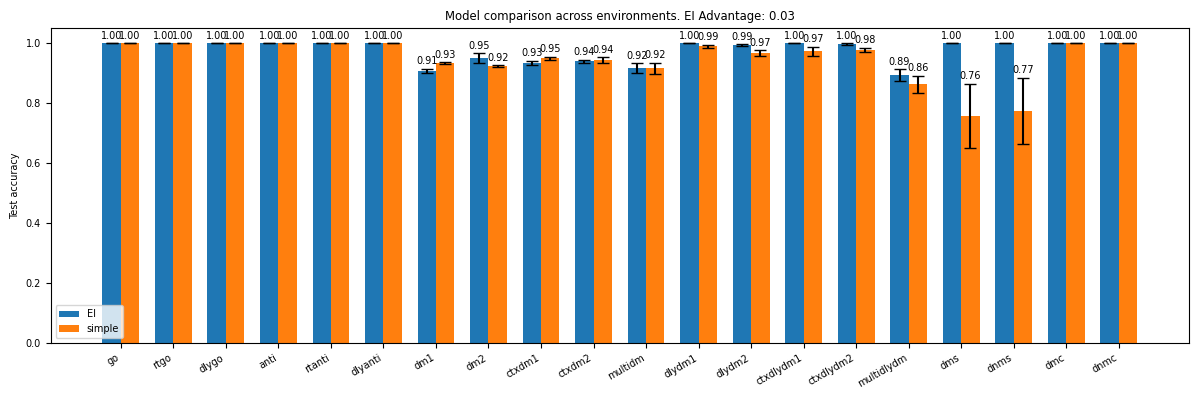

In [37]:
plot_test_performance(test_dict[0]['performance']['ei'], test_dict[0]['performance']['simple'],
                      env_names, show_values=True)

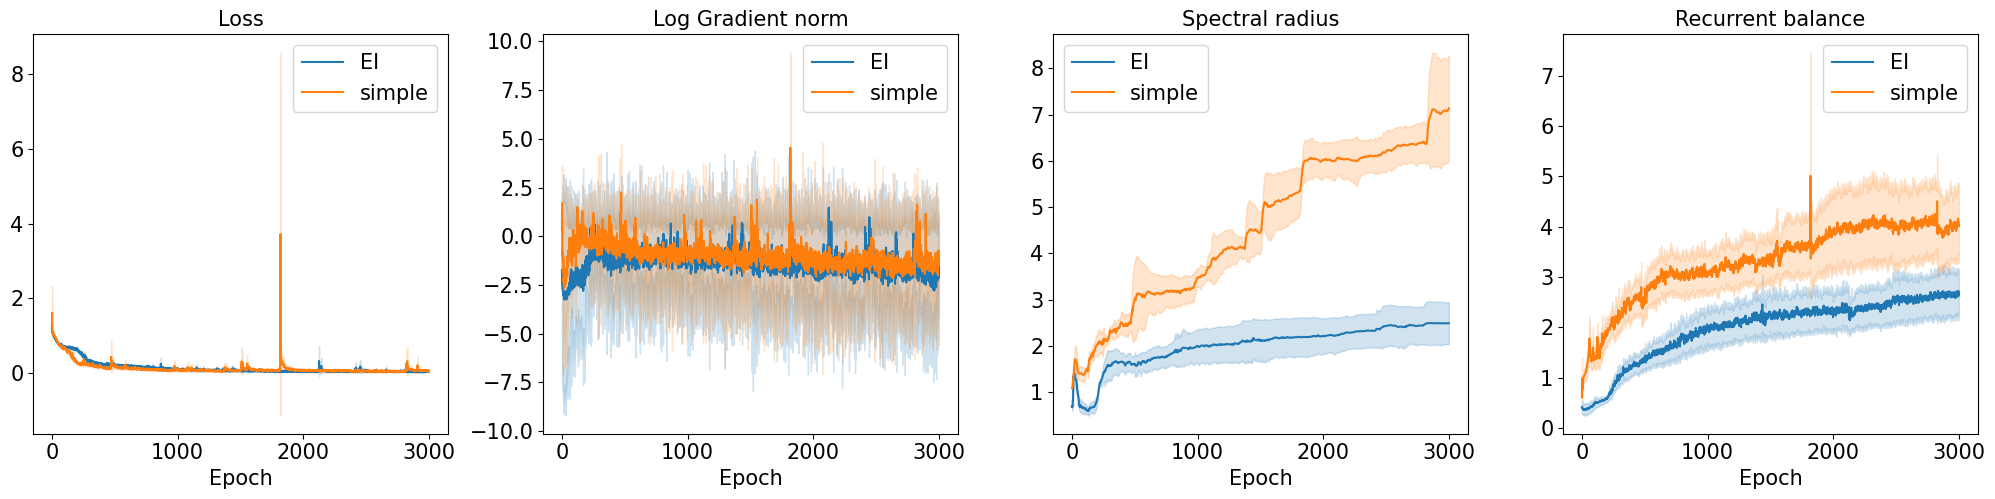

In [38]:
idx = 0
plot_loss_curve(test_dict[idx]['loss_log']['ei'], test_dict[idx]['gradient_log']['ei'],
                test_dict[idx]['loss_log']['simple'], test_dict[idx]['gradient_log']['simple'],
                test_dict[idx]['spectral_radius_log']['ei'], test_dict[idx]['spectral_radius_log']['simple'],
                test_dict[idx]['rec_balance_log']['ei'], test_dict[idx]['rec_balance_log']['simple'])